# Measures of Central Tendency
---

## Experiment: an outlier and the sample mean.

Mean: 56.00 -> 69.09


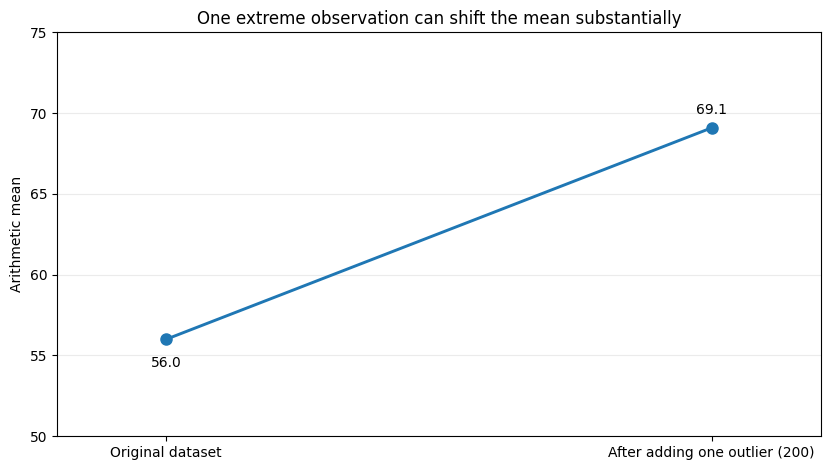

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.array([42, 47, 50, 51, 55, 58, 60, 62, 65, 70], dtype=float)
with_outlier = np.append(data, 200)

means = [np.mean(data), np.mean(with_outlier)]
print(f"Mean: {means[0]:.2f} -> {means[1]:.2f}")

x = np.arange(2)

fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.plot(x, means, marker="o", linewidth=2.1, markersize=8)

for i, value in enumerate(means):
    ax.annotate(f"{value:.1f}", (i, value), xytext=(0, -20 if i == 0 else 10),
                textcoords="offset points", ha="center", fontsize=10)

ax.set_xticks(x, ["Original dataset", "After adding one outlier (200)"])
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(50, 75)
ax.set_ylabel("Arithmetic mean")
ax.set_title("One extreme observation can shift the mean substantially")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig("../../images/means_outlier_experiment.png", dpi=180, bbox_inches="tight")
plt.show()

## Experiment: averaging subgroup means correctly.

In [2]:
import numpy as np

group_sizes = np.array([10, 90])
group_means = np.array([80.0, 60.0])

naive_mean = np.mean(group_means)  # Treats the groups as equally large.
overall_mean = np.average(group_means, weights=group_sizes)

print(f"Unweighted mean of group means: {naive_mean:.1f}")
print(f"Mean over all individuals:    {overall_mean:.1f}")

Unweighted mean of group means: 70.0
Mean over all individuals:    62.0


## Experiment: conversion rates in a Pandas DataFrame.

In [3]:
import pandas as pd

# Counts and conversion rates reported for four days/channels.
daily = pd.DataFrame({
    "channel": ["Organic", "Organic", "Ads", "Ads"],
    "sessions": [100, 120, 10, 20],
    "conversions": [4, 6, 2, 2],
})
daily["conversion_rate"] = daily["conversions"] / daily["sessions"]

# Incorrect if we want the rate over ALL sessions:
average_of_rates = daily["conversion_rate"].mean()

# Correct: ratio of totals = denominator-weighted mean of rates.
overall_rate = daily["conversions"].sum() / daily["sessions"].sum()
by_channel = daily.groupby("channel", as_index=False).agg(
    sessions=("sessions", "sum"),
    conversions=("conversions", "sum"),
)
by_channel["conversion_rate"] = (
    by_channel["conversions"] / by_channel["sessions"]
)

print(f"Naive mean of four rates: {average_of_rates:.2%}")
print(f"Overall session conversion rate: {overall_rate:.2%}")
print(by_channel.to_string(index=False))

Naive mean of four rates: 9.75%
Overall session conversion rate: 5.60%
channel  sessions  conversions  conversion_rate
    Ads        30            4         0.133333
Organic       220           10         0.045455


## Experiment: the annualized compound growth rate.

In [4]:
from math import prod
from scipy.stats import gmean

annual_rates = [0.02, 0.05]
growth_factors = [1 + rate for rate in annual_rates]
initial_population = 1_000_000

actual_final = initial_population * prod(growth_factors)
equivalent_factor = gmean(growth_factors)
equivalent_rate = equivalent_factor - 1
reproduced_final = initial_population * equivalent_factor ** len(annual_rates)

print(f"Final population: {actual_final:,.0f}")
print(f"Equivalent annual growth: {100 * equivalent_rate:.4f}%")
print(f"Reproduced final population: {reproduced_final:,.0f}")

# The rates can also be negative, as long as each growth factor is positive.
# Try [0.40, -0.20].

Final population: 1,071,000
Equivalent annual growth: 3.4891%
Reproduced final population: 1,071,000


## Experiment: equal distances and population density.

In [5]:
from scipy.stats import hmean

# Equal distances: the harmonic mean of the speeds is appropriate.
speeds = [50.0, 40.0]  # km/h
distance_each_way = 100.0  # km
direct_average_speed = (2 * distance_each_way) / sum(
    distance_each_way / speed for speed in speeds
)
print(f"Overall average speed: {direct_average_speed:.4f} km/h")
print(f"Harmonic mean of speeds: {hmean(speeds):.4f} km/h")

# Total population / total area gives the combined density.
densities = [50.0, 40.0]    # people/km^2
populations = [1000, 3000]  # people
areas = [pop / density for pop, density in zip(populations, densities)]
combined_density = sum(populations) / sum(areas)
weighted_harmonic = hmean(densities, weights=populations)
print(f"Combined density: {combined_density:.4f} people/km^2")
print(f"Weighted harmonic mean: {weighted_harmonic:.4f} people/km^2")

Overall average speed: 44.4444 km/h
Harmonic mean of speeds: 44.4444 km/h
Combined density: 42.1053 people/km^2
Weighted harmonic mean: 42.1053 people/km^2


## Experiment: compare the four means.

In [6]:
import numpy as np
from scipy.stats import gmean, hmean

values = np.array([2.0, 4.0, 8.0])
quadratic = np.sqrt(np.mean(values ** 2))
arithmetic = np.mean(values)
geometric = gmean(values)
harmonic = hmean(values)

print(f"QM = {quadratic:.4f}")
print(f"AM = {arithmetic:.4f}")
print(f"GM = {geometric:.4f}")
print(f"HM = {harmonic:.4f}")

QM = 5.2915
AM = 4.6667
GM = 4.0000
HM = 3.4286


## Experiment: missing observations and the mean.

In [7]:
import numpy as np

observations = np.array([42.0, 48.0, np.nan, 60.0])
print("Ordinary mean:", np.mean(observations))  # nan
print("Mean of observed values:", np.nanmean(observations))  # 50.0

Ordinary mean: nan
Mean of observed values: 50.0


## Experiment: computing the sample median.

In [8]:
import numpy as np

odd_sample = np.array([8, 2, 5, 10, 3])
even_sample = np.array([8, 2, 5, 10])

print("Odd sample:", np.sort(odd_sample))
print("Median:", np.median(odd_sample))

print("Even sample:", np.sort(even_sample))
print("Median:", np.median(even_sample))

Odd sample: [ 2  3  5  8 10]
Median: 5.0
Even sample: [ 2  5  8 10]
Median: 6.5


## Experiment: absolute and squared loss

Mean: 6.50
Median: 2.50


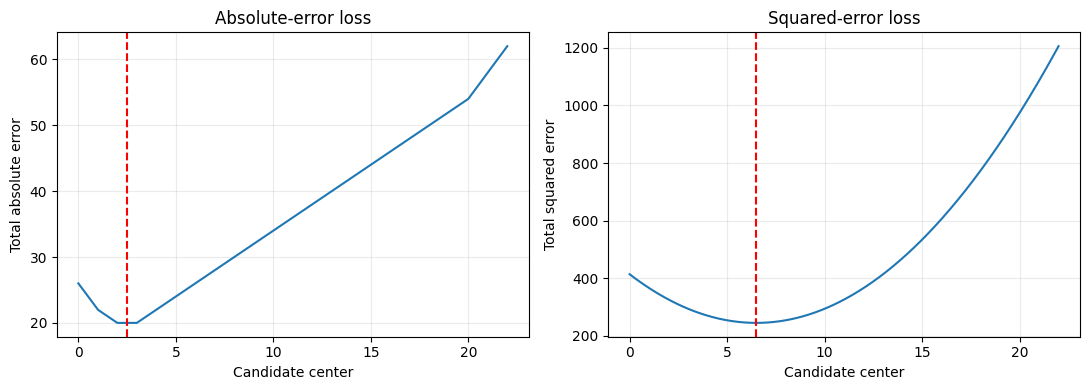

In [9]:
import numpy as np
import matplotlib.pyplot as plt

data = np.array([1.0, 2.0, 3.0, 20.0])
centers = np.linspace(0, 22, 500)

absolute_loss = np.sum(np.abs(data[:, None] - centers[None, :]), axis=0)

squared_loss = np.sum((data[:, None] - centers[None, :]) ** 2, axis=0)

mean = np.mean(data)
median = np.median(data)

print(f"Mean: {mean:.2f}")
print(f"Median: {median:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(centers, absolute_loss)
axes[0].axvline(median, color="red", linestyle="--")
axes[0].set_title("Absolute-error loss")
axes[0].set_xlabel("Candidate center")
axes[0].set_ylabel("Total absolute error")

axes[1].plot(centers, squared_loss)
axes[1].axvline(mean, color="red", linestyle="--")
axes[1].set_title("Squared-error loss")
axes[1].set_xlabel("Candidate center")
axes[1].set_ylabel("Total squared error")

for ax in axes:
    ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    "../../images/median_absolute_vs_squared_loss.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

## Experiment: mean and median in grouped data

In [10]:
import pandas as pd

transactions = pd.DataFrame({
    "store": ["A", "A", "A", "A", "B", "B", "B", "B"],
    "amount": [40, 50, 60, 500, 40, 45, 50, 55]
})

summary = transactions.groupby("store")["amount"].agg(
    count="count",
    mean="mean",
    median="median",
    total="sum"
)

print(summary)

       count   mean  median  total
store                             
A          4  162.5    55.0    650
B          4   47.5    47.5    190


## Experiment: comparing quantile conventions.

In [11]:
import numpy as np

data = np.array([10, 20, 30, 40])

probabilities = [0.25, 0.50, 0.75]

for p in probabilities:
    inverse_cdf = np.quantile(data, p, method="inverted_cdf")
    linear = np.quantile(data, p, method="linear")

    print(
        f"p={p:.2f}: "
        f"inverse CDF={inverse_cdf:.2f}, "
        f"linear={linear:.2f}"
    )

# A percentile uses a percentage rather than a probability.
print("25th percentile:", np.percentile(data, 25))


def satisfies_coverage(values, p, y):
    below = np.mean(values < y)
    above = np.mean(values > y)

    return below <= p and above <= 1 - p


# At p=0.20, the linear method returns 16,
# which is not an empirical p-quantile under
# the coverage definition given above.
p = 0.20

for method in ["inverted_cdf", "linear"]:
    y = np.quantile(data, p, method=method)

    print(
        f"{method}: {y:.2f}, "
        f"coverage conditions: "
        f"{satisfies_coverage(data, p, y)}"
    )

# Repeat the experiment with [10, 20, 30, 1000].
# Compare several probabilities and methods.

p=0.25: inverse CDF=10.00, linear=17.50
p=0.50: inverse CDF=20.00, linear=25.00
p=0.75: inverse CDF=30.00, linear=32.50
25th percentile: 17.5
inverted_cdf: 10.00, coverage conditions: True
linear: 16.00, coverage conditions: False


## Experiment: grouped response-time percentiles.

In [1]:
import pandas as pd

responses = pd.DataFrame({
    "service": ["A"] * 6 + ["B"] * 6,
    "latency_ms": [
        80, 100, 110, 120, 125, 600,
        140, 145, 160, 170, 200, 260
    ]
})

summary = responses.groupby("service")["latency_ms"].agg(
    count="count",
    median="median",
    p95=lambda x: x.quantile(0.95)
)

print(summary)

# Calculate the 95th percentile across all responses.
overall_p95 = responses["latency_ms"].quantile(0.95)

print(f"Overall p95: {overall_p95:.2f} ms")

# Experiment: replace the response time 600 by 6000.
# Compare the effect on the median and p95.

         count  median     p95
service                       
A            6   115.0  481.25
B            6   165.0  245.00
Overall p95: 413.00 ms


## Experiment: sampling variability of quantiles.

Sample size: 40
SD of medians: 0.1933
SD of p95 estimates: 1.6576

Sample size: 400
SD of medians: 0.0622
SD of p95 estimates: 0.5310



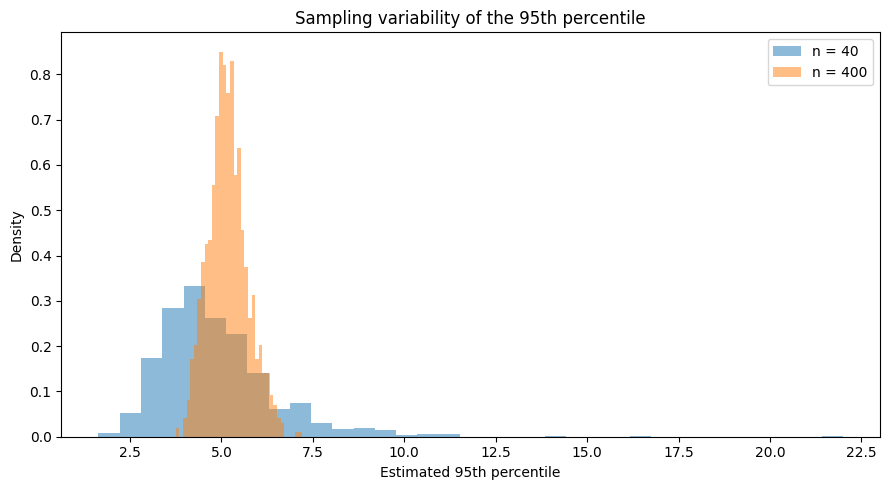

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

repetitions = 1000
sample_sizes = [40, 400]

p95_estimates = {}

for n in sample_sizes:
    samples = rng.lognormal(mean=0.0, sigma=1.0, size=(repetitions, n))

    medians = np.quantile(samples, 0.50, axis=1)
    
    p95 = np.quantile(samples, 0.95, axis=1)

    p95_estimates[n] = p95

    print(f"Sample size: {n}")
    print(f"SD of medians: {np.std(medians, ddof=1):.4f}")
    print(f"SD of p95 estimates: {np.std(p95, ddof=1):.4f}")
    print()

fig, ax = plt.subplots(figsize=(9, 5))

for n in sample_sizes:
    ax.hist(
        p95_estimates[n],
        bins=35,
        density=True,
        alpha=0.5,
        label=f"n = {n}"
    )

ax.set_xlabel("Estimated 95th percentile")
ax.set_ylabel("Density")
ax.set_title("Sampling variability of the 95th percentile")
ax.legend()

fig.tight_layout()
fig.savefig(
    "../../images/quantile_sampling_variability.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment by replacing p95 with p99.
# How does the sampling variability change?

## Experiment: modes of numerical and categorical data.

In [3]:
import pandas as pd

numerical = pd.Series([2, 3, 3, 4, 4, 5, 6])
categorical = pd.Series([
    "Card", "Cash", "Card", "Transfer",
    "Cash", "Card", "Cash"
])

print("Numerical modes:", numerical.mode().tolist())
print("Categorical modes:", categorical.mode().tolist())

print("\nCategory frequencies:")
print(categorical.value_counts())

# Experiment: make all numerical observations unique.
# What does Series.mode() return?

Numerical modes: [3, 4]
Categorical modes: ['Card', 'Cash']

Category frequencies:
Card        3
Cash        3
Transfer    1
Name: count, dtype: int64


## Experiment: histogram bin widths and modes 

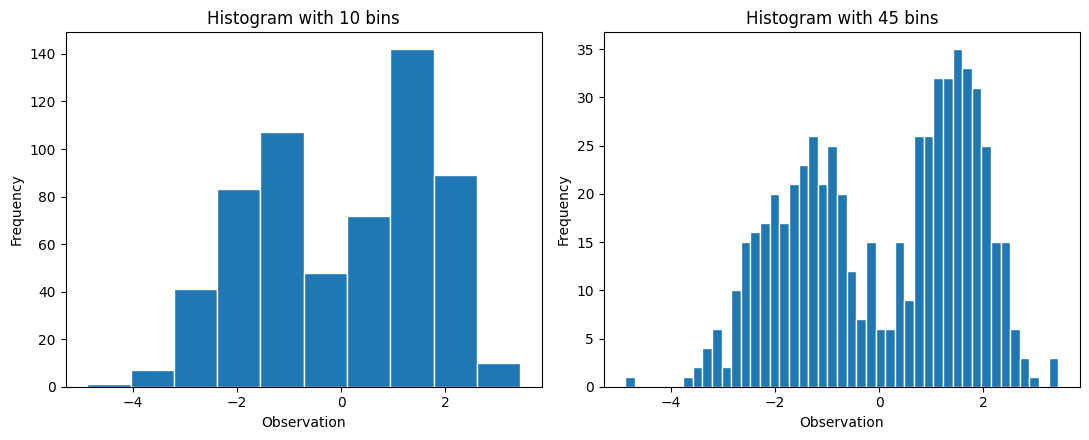

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

# Generate observations from a mixture of two distributions.
sample = np.concatenate([
    rng.normal(loc=-1.5, scale=0.9, size=300),
    rng.normal(loc=1.5, scale=0.6, size=300)
])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, bins in zip(axes, [10, 45]):
    ax.hist(sample, bins=bins, edgecolor="white")
    ax.set_title(f"Histogram with {bins} bins")
    ax.set_xlabel("Observation")
    ax.set_ylabel("Frequency")

fig.tight_layout()
fig.savefig(
    "../../images/histogram_bin_width_and_modes.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: change the number of observations.
# What happens to the apparent peaks?

## Experiment: computing the five-number summary.

In [7]:
import numpy as np

data = np.array([4, 5, 6, 8, 9, 10, 11, 15, 31])

q1, median, q3 = np.quantile(
    data, [0.25, 0.50, 0.75],
    method="linear"
)

summary = {
    "Minimum": np.min(data),
    "Q1": q1,
    "Median": median,
    "Q3": q3,
    "Maximum": np.max(data)
}

for name, value in summary.items():
    print(f"{name}: {value:.2f}")

print("\nUsing the inverted CDF method:")
print(
    np.quantile(
        data, [0.25, 0.50, 0.75],
        method="inverted_cdf"
    )
)

# Experiment: replace 31 by 1000.
# Which elements of the summary change?

Minimum: 4.00
Q1: 6.00
Median: 9.00
Q3: 11.00
Maximum: 31.00

Using the inverted CDF method:
[ 6  9 11]


## Experiment: IQR fences and box plots.

Q1: 6.00
Q3: 11.00
IQR: 5.00
Lower fence: -1.50
Upper fence: 18.50
Flagged observations: [31]


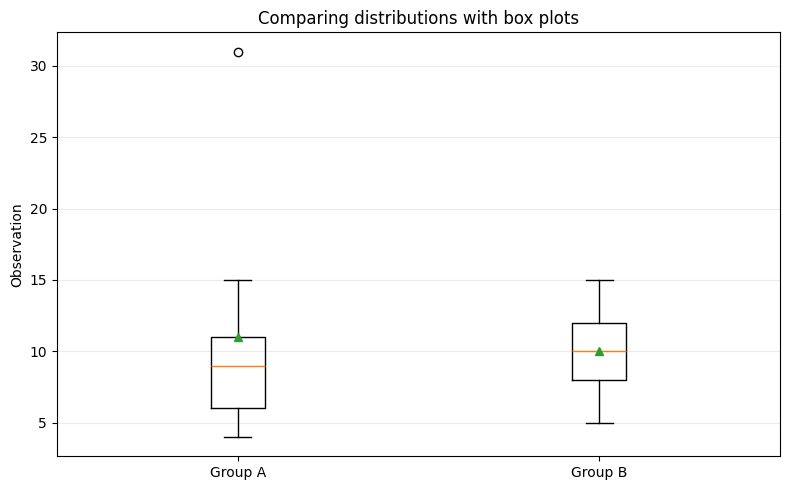

In [9]:
import numpy as np
import matplotlib.pyplot as plt

group_a = np.array([4, 5, 6, 8, 9, 10, 11, 15, 31])
group_b = np.array([5, 7, 8, 9, 10, 11, 12, 13, 15])

q1, q3 = np.quantile(
    group_a, [0.25, 0.75],
    method="linear"
)

iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = group_a[
    (group_a < lower_fence) |
    (group_a > upper_fence)
]

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower fence: {lower_fence:.2f}")
print(f"Upper fence: {upper_fence:.2f}")
print("Flagged observations:", outliers)

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [group_a, group_b],
    whis=1.5,
    showmeans=True
)

ax.set_xticks([1, 2], ["Group A", "Group B"])
ax.set_ylabel("Observation")
ax.set_title("Comparing distributions with box plots")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    "../../images/iqr_boxplots.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: change the observation 31 to 1000.
# How do the fences and whiskers change?

## Experiment: outlier flags in normally distributed data.

In [10]:
import numpy as np

rng = np.random.default_rng(2026)

repetitions = 300
sample_sizes = [30, 300, 3000]

for n in sample_sizes:
    samples = rng.normal(
        loc=0.0,
        scale=1.0,
        size=(repetitions, n)
    )

    q1, q3 = np.quantile(
        samples,
        [0.25, 0.75],
        axis=1,
        method="linear"
    )

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (
        (samples < lower[:, None]) |
        (samples > upper[:, None])
    )

    proportion_flagged = flagged.mean()
    samples_with_flags = flagged.any(axis=1).mean()

    print(f"Sample size: {n}")
    print(
        f"Flagged observations: "
        f"{proportion_flagged:.2%}"
    )
    print(
        f"Samples with at least one flag: "
        f"{samples_with_flags:.2%}"
    )
    print()

# Experiment: repeat with a lognormal distribution.
# Does the rule flag more observations in the upper tail?

Sample size: 30
Flagged observations: 1.58%
Samples with at least one flag: 27.67%

Sample size: 300
Flagged observations: 0.78%
Samples with at least one flag: 86.33%

Sample size: 3000
Flagged observations: 0.72%
Samples with at least one flag: 100.00%



## Experiment: MAD versus standard deviation.

In [11]:
import numpy as np
from scipy.stats import median_abs_deviation

original = np.array(
    [10, 11, 12, 13, 14, 15, 16, 17, 18],
    dtype=float
)

modified = original.copy()
modified[-1] = 1000.0

for name, data in [
    ("Original", original),
    ("Modified", modified)
]:
    standard_deviation = np.std(data, ddof=1)
    median = np.median(data)
    mad = median_abs_deviation(data, scale=1)
    scaled_mad = median_abs_deviation(
        data, scale="normal"
    )

    print(name)
    print(f"Median: {median:.2f}")
    print(f"Standard deviation: {standard_deviation:.2f}")
    print(f"Raw MAD: {mad:.2f}")
    print(f"Normal-scaled MAD: {scaled_mad:.2f}")
    print()

# Experiment: replace several observations by
# increasingly large values.
# When does the MAD begin to change substantially?

Original
Median: 14.00
Standard deviation: 2.74
Raw MAD: 2.00
Normal-scaled MAD: 2.97

Modified
Median: 14.00
Standard deviation: 328.84
Raw MAD: 2.00
Normal-scaled MAD: 2.97

